# Advanced LoRaWAN Security: Edge-IIoTset + Federated Intrusion Detection + Threat-Aware RL
**Google Colab full implementation notebook**

Research extension of the published LoRaWAN DRL paper. This notebook uses the exact Kaggle dataset specified by the researcher:
https://www.kaggle.com/datasets/mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot

## Evidence boundaries
- Edge-IIoTset experiments are **network intrusion detection** experiments.
- Federated clients are simulated partitions of the dataset.
- LoRa radio PDR/latency/energy in this notebook are generated by an **abstract simulator**, not physical measurements.
- AES-GCM cells demonstrate authenticated encryption, tamper rejection and replay checks; they are not a formal security proof.
- Do not invent or pre-fill results. Run all cells and report the outputs obtained.

## Section 1 — Setup and dataset acquisition

The Kaggle dataset includes a selected ML/DL CSV. The dataset page documents the file as `DNN-EdgeIIoT-dataset.csv`, with labels such as `Attack_label` and `Attack_type`. The archive is large; start with a stratified sample for development, then repeat with a larger/full dataset if Colab RAM and runtime permit.

Dataset page: https://www.kaggle.com/datasets/mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot
Dataset paper DOI: https://doi.org/10.1109/ACCESS.2022.3165809

In [1]:
!pip -q install kaggle pandas numpy scikit-learn matplotlib seaborn imbalanced-learn cryptography

In [5]:
# Upload kaggle.json from Kaggle > Account > Create New Token.
from google.colab import files
import os, pathlib, shutil, subprocess, glob
KAGGLE_DIR = pathlib.Path.home()/".kaggle"
KAGGLE_DIR.mkdir(exist_ok=True)
if not (KAGGLE_DIR/"kaggle.json").exists():
    uploaded = files.upload()
    if "kaggle.json" in uploaded:
        shutil.copy("kaggle.json", KAGGLE_DIR/"kaggle.json")
        os.chmod(KAGGLE_DIR/"kaggle.json", 0o600)
    else:
        print("No kaggle.json found. You can upload the CSV manually in the fallback cell.")

Saving kaggle.json to kaggle.json


In [3]:
# Download the selected CSV from the requested Kaggle dataset.
DATASET_SLUG = "mohamedamineferrag/edgeiiotset-cyber-security-dataset-of-iot-iiot"
DOWNLOAD_DIR = "/content/edgeiiot"
os.makedirs(DOWNLOAD_DIR, exist_ok=True)
CSV_PATH = None
if (KAGGLE_DIR/"kaggle.json").exists():
    cmd = [
        "kaggle", "datasets", "download", "-d", DATASET_SLUG,
        "-f", "Edge-IIoTset dataset/Selected dataset for ML and DL/DNN-EdgeIIoT-dataset.csv",
        "-p", DOWNLOAD_DIR, "--unzip"
    ]
    res = subprocess.run(cmd, capture_output=True, text=True)
    print(res.stdout[-1500:])
    if res.returncode != 0:
        print(res.stderr[-2500:])
    matches = glob.glob(DOWNLOAD_DIR+"/**/DNN-EdgeIIoT-dataset.csv", recursive=True)
    if matches:
        CSV_PATH = matches[0]
print("CSV_PATH:", CSV_PATH)

CSV_PATH: None


In [7]:
# Fallback: upload the CSV manually if Kaggle CLI download did not succeed.
if CSV_PATH is None:
    up = files.upload()
    csvs = [n for n in up if n.lower().endswith(".csv")]
    if csvs:
        CSV_PATH = csvs[0]
assert CSV_PATH and os.path.exists(CSV_PATH), "CSV unavailable. Upload DNN-EdgeIIoT-dataset.csv."
print("Using:", CSV_PATH)

Saving DNN-EdgeIIoT-dataset.csv to DNN-EdgeIIoT-dataset.csv
Using: DNN-EdgeIIoT-dataset.csv


## Section 2 — Dataset inspection and preprocessing

We evaluate both binary detection (`Attack_label`) and multiclass attack classification (`Attack_type`). Leakage-prone addresses, timestamps, raw payloads, and identifiers are excluded where present. Preprocessing is fitted on the training partition only. A fixed seed is used for reproducibility.

Because the dataset can be large, `SAMPLE_FRAC` controls a stratified development sample. For final results, increase it to 1.0 when feasible and document the setting.

In [8]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import random, time, json, warnings, gc
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
    precision_recall_fscore_support, f1_score, precision_score, recall_score,
    roc_auc_score, roc_curve, balanced_accuracy_score)
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import SGDClassifier
warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED)
df = pd.read_csv(CSV_PATH, low_memory=False)
print("Raw shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Raw shape: (2219201, 63)
Columns: ['frame.time', 'ip.src_host', 'ip.dst_host', 'arp.dst.proto_ipv4', 'arp.opcode', 'arp.hw.size', 'arp.src.proto_ipv4', 'icmp.checksum', 'icmp.seq_le', 'icmp.transmit_timestamp', 'icmp.unused', 'http.file_data', 'http.content_length', 'http.request.uri.query', 'http.request.method', 'http.referer', 'http.request.full_uri', 'http.request.version', 'http.response', 'http.tls_port', 'tcp.ack', 'tcp.ack_raw', 'tcp.checksum', 'tcp.connection.fin', 'tcp.connection.rst', 'tcp.connection.syn', 'tcp.connection.synack', 'tcp.dstport', 'tcp.flags', 'tcp.flags.ack', 'tcp.len', 'tcp.options', 'tcp.payload', 'tcp.seq', 'tcp.srcport', 'udp.port', 'udp.stream', 'udp.time_delta', 'dns.qry.name', 'dns.qry.name.len', 'dns.qry.qu', 'dns.qry.type', 'dns.retransmission', 'dns.retransmit_request', 'dns.retransmit_request_in', 'mqtt.conack.flags', 'mqtt.conflag.cleansess', 'mqtt.conflags', 'mqtt.hdrflags', 'mqtt.len', 'mqtt.msg_decoded_as', 'mqtt.msg', 'mqtt.msgtype', 'mqtt.pro

,frame.time,ip.src_host,ip.dst_host,arp.dst.proto_ipv4,arp.opcode,arp.hw.size,arp.src.proto_ipv4,icmp.checksum,icmp.seq_le,icmp.transmit_timestamp,...,mqtt.proto_len,mqtt.protoname,mqtt.topic,mqtt.topic_len,mqtt.ver,mbtcp.len,mbtcp.trans_id,mbtcp.unit_id,Attack_label,Attack_type
0,2021 11:44:10.081753000,192.168.0.128,192.168.0.101,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0,Normal
1,2021 11:44:10.162218000,192.168.0.101,192.168.0.128,0,0.0,0.0,0,0.0,0.0,0.0,...,4.0,MQTT,0,0.0,4.0,0.0,0.0,0.0,0,Normal
2,2021 11:44:10.162271000,192.168.0.128,192.168.0.101,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0,Normal
3,2021 11:44:10.162641000,192.168.0.128,192.168.0.101,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,0,0.0,0.0,0.0,0.0,0.0,0,Normal
4,2021 11:44:10.166132000,192.168.0.101,192.168.0.128,0,0.0,0.0,0,0.0,0.0,0.0,...,0.0,0,Temperature_and_Humidity,24.0,0.0,0.0,0.0,0.0,0,Normal


In [9]:
print("Attack_type counts:")
if "Attack_type" in df.columns:
    display(df["Attack_type"].value_counts(dropna=False).to_frame("count"))
print("Attack_label counts:")
if "Attack_label" in df.columns:
    display(df["Attack_label"].value_counts(dropna=False).to_frame("count"))

Attack_type counts:


,count
Attack_type,
Normal,1615643
DDoS_UDP,121568
DDoS_ICMP,116436
SQL_injection,51203
Password,50153
Vulnerability_scanner,50110
DDoS_TCP,50062
DDoS_HTTP,49911
Uploading,37634


Attack_label counts:


,count
Attack_label,
0,1615643
1,603558


In [10]:
# Stratified sample by multiclass target to reduce RAM for initial development.
SAMPLE_FRAC = 0.20  # set to 1.0 for full data if resources allow
TARGET_MULTI = "Attack_type" if "Attack_type" in df.columns else None
if SAMPLE_FRAC < 1 and TARGET_MULTI:
    df = (df.groupby(TARGET_MULTI, group_keys=False)
            .apply(lambda g: g.sample(n=max(1, int(len(g)*SAMPLE_FRAC)),
                                      random_state=SEED) if len(g)>1 else g)
            .reset_index(drop=True))
print("Working shape:", df.shape)

Working shape: (443834, 63)


In [11]:
# Remove known high-risk/leakage-prone columns when present.
drop_candidates = [
    "frame.time", "ip.src_host", "ip.dst_host", "arp.src.proto_ipv4", "arp.dst.proto_ipv4",
    "http.file_data", "http.request.full_uri", "icmp.transmit_timestamp",
    "http.request.uri.query", "tcp.options", "tcp.payload", "tcp.srcport",
    "tcp.dstport", "udp.port", "mqtt.msg"
]
label_cols = [c for c in ["Attack_label", "Attack_type"] if c in df.columns]
drop_cols = [c for c in drop_candidates if c in df.columns]
features = df.drop(columns=label_cols + drop_cols, errors="ignore").copy()
features = features.replace([np.inf, -np.inf], np.nan)
# Drop all-null, >60% missing, and constant features
features = features.loc[:, features.notna().any()]
features = features.loc[:, features.isna().mean() < 0.60]
features = features.loc[:, features.nunique(dropna=True) > 1]
# Drop very high-cardinality object columns to avoid huge one-hot expansion
for col in features.select_dtypes(include=["object", "category"]).columns.tolist():
    if features[col].nunique(dropna=True) > 40:
        features.drop(columns=col, inplace=True)
print("Feature shape after filtering:", features.shape)
print("Categorical:", features.select_dtypes(include=["object","category"]).columns.tolist())

Feature shape after filtering: (443834, 42)
Categorical: ['http.request.method', 'http.referer', 'http.request.version', 'dns.qry.name.len', 'mqtt.conack.flags', 'mqtt.protoname', 'mqtt.topic']


## Section 3 — Centralized intrusion detection

The primary task is multiclass classification of `Attack_type`; the secondary task is binary normal-vs-attack classification using `Attack_label` where available. The code below uses a stratified split and training-only preprocessing. Metrics include macro-F1 and balanced accuracy, which are important when classes are imbalanced.

In [12]:
# Multiclass task
if "Attack_type" not in df.columns:
    raise ValueError("Attack_type label not found. Inspect dataset columns and select a target.")
y_multi = df["Attack_type"].astype(str)
X_train, X_test, y_train_multi, y_test_multi = train_test_split(
    features, y_multi, test_size=0.20, random_state=SEED, stratify=y_multi
)
X_train, X_val, y_train_multi, y_val_multi = train_test_split(
    X_train, y_train_multi, test_size=0.20, random_state=SEED, stratify=y_train_multi
)
num_cols = X_train.select_dtypes(exclude=["object","category"]).columns.tolist()
cat_cols = X_train.select_dtypes(include=["object","category"]).columns.tolist()
try:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("ohe", ohe)]), cat_cols)
], remainder="drop")
Xtr = preprocessor.fit_transform(X_train)
Xva = preprocessor.transform(X_val)
Xte = preprocessor.transform(X_test)
print("Transformed:", Xtr.shape, Xva.shape, Xte.shape)

Transformed: (284053, 71) (71014, 71) (88767, 71)


In [13]:
# Centralized Extra Trees baseline
central_multi = ExtraTreesClassifier(n_estimators=250, random_state=SEED, n_jobs=-1,
                                     class_weight="balanced")
t0=time.time()
central_multi.fit(Xtr, y_train_multi)
central_train_seconds=time.time()-t0
pred_multi = central_multi.predict(Xte)
print("Training time (seconds):", round(central_train_seconds,2))
print(classification_report(y_test_multi, pred_multi, digits=4, zero_division=0))
print("Accuracy:", accuracy_score(y_test_multi,pred_multi))
print("Balanced accuracy:", balanced_accuracy_score(y_test_multi,pred_multi))
print("Macro F1:", f1_score(y_test_multi,pred_multi,average="macro",zero_division=0))
print("Weighted F1:", f1_score(y_test_multi,pred_multi,average="weighted",zero_division=0))

Training time (seconds): 48.24
                       precision    recall  f1-score   support

             Backdoor     0.9681    0.9165    0.9416       994
            DDoS_HTTP     0.9214    0.9274    0.9243      1996
            DDoS_ICMP     0.9991    0.9994    0.9992      4658
             DDoS_TCP     1.0000    1.0000    1.0000      2002
             DDoS_UDP     1.0000    1.0000    1.0000      4863
       Fingerprinting     0.1854    0.7000    0.2932        40
                 MITM     1.0000    1.0000    1.0000        48
               Normal     1.0000    1.0000    1.0000     64626
             Password     0.8134    0.8475    0.8301      2006
        Port_Scanning     0.9313    0.9313    0.9313       902
           Ransomware     0.9074    0.7849    0.8417       437
        SQL_injection     0.8370    0.8276    0.8323      2048
            Uploading     0.8241    0.7907    0.8071      1505
Vulnerability_scanner     0.9692    0.9431    0.9560      2005
                  XSS  

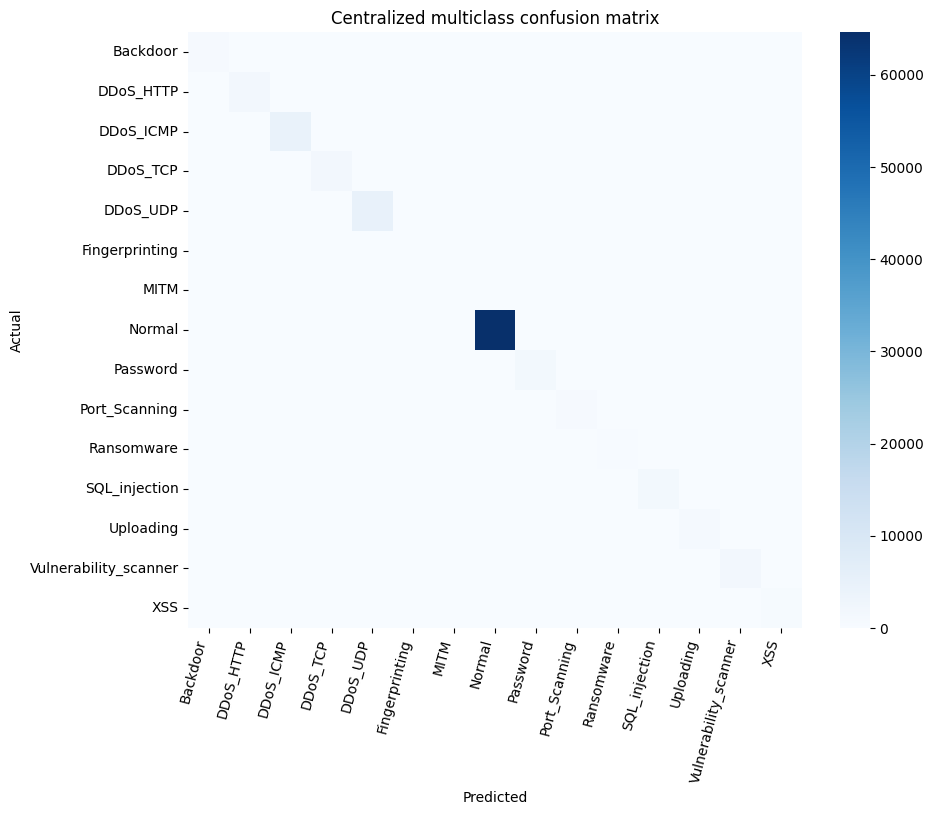

In [14]:
# Confusion matrix (may be large if many classes)
labels = sorted(pd.Series(y_test_multi).unique())
cm = confusion_matrix(y_test_multi, pred_multi, labels=labels)
plt.figure(figsize=(max(8,len(labels)*0.65), max(6,len(labels)*0.55)))
sns.heatmap(cm, annot=(len(labels)<=12), fmt="d", cmap="Blues",
            xticklabels=labels, yticklabels=labels)
plt.title("Centralized multiclass confusion matrix")
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.xticks(rotation=75, ha="right")
plt.yticks(rotation=0); plt.tight_layout(); plt.show()

### 3.1 Binary intrusion detection
If `Attack_label` is present, evaluate it separately. This avoids conflating attack-type classification with normal-vs-malicious detection.

              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000     64626
           1     1.0000    1.0000    1.0000     24141

    accuracy                         1.0000     88767
   macro avg     1.0000    1.0000    1.0000     88767
weighted avg     1.0000    1.0000    1.0000     88767

Binary accuracy: 1.0 Macro-F1: 1.0
Binary ROC-AUC: 1.0


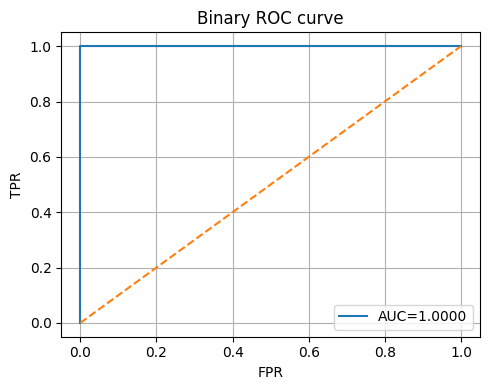

In [15]:
if "Attack_label" in df.columns:
    y_binary = pd.to_numeric(df["Attack_label"], errors="coerce").fillna(0).astype(int)
    Xb = features.copy()
    Xb_train, Xb_test, yb_train, yb_test = train_test_split(
        Xb, y_binary, test_size=0.20, random_state=SEED, stratify=y_binary
    )
    nb = Xb_train.select_dtypes(exclude=["object","category"]).columns.tolist()
    cb = Xb_train.select_dtypes(include=["object","category"]).columns.tolist()
    try:
        oheb = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        oheb = OneHotEncoder(handle_unknown="ignore", sparse=False)
    prep_b = ColumnTransformer([
        ("num", Pipeline([("imp",SimpleImputer(strategy="median")),("sc",StandardScaler())]),nb),
        ("cat", Pipeline([("imp",SimpleImputer(strategy="most_frequent")),("oh",oheb)]),cb)
    ])
    Xbtr=prep_b.fit_transform(Xb_train); Xbte=prep_b.transform(Xb_test)
    binary_model=ExtraTreesClassifier(n_estimators=250,random_state=SEED,n_jobs=-1,class_weight="balanced")
    binary_model.fit(Xbtr,yb_train)
    pb=binary_model.predict(Xbte)
    print(classification_report(yb_test,pb,digits=4,zero_division=0))
    print("Binary accuracy:",accuracy_score(yb_test,pb),"Macro-F1:",f1_score(yb_test,pb,average="macro"))
    if hasattr(binary_model,"predict_proba"):
        pscore=binary_model.predict_proba(Xbte)[:,list(binary_model.classes_).index(1)]
        print("Binary ROC-AUC:",roc_auc_score(yb_test,pscore))
        fpr,tpr,_=roc_curve(yb_test,pscore)
        plt.figure(figsize=(5,4)); plt.plot(fpr,tpr,label=f"AUC={roc_auc_score(yb_test,pscore):.4f}")
        plt.plot([0,1],[0,1],"--"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title("Binary ROC curve")
        plt.legend(); plt.grid(True); plt.tight_layout(); plt.show()
else:
    print("Attack_label not found; binary task skipped.")

## Section 4 — Federated intrusion detection

Clients are simulated by splitting training rows into local partitions. This demonstrates a federated experimental setup, but the random partitions are not evidence of real geographic/device heterogeneity. The following implementation uses a linear SGD classifier with log-loss and weighted averaging of local model parameters. This is an interpretable federated baseline; it is not equivalent to federated DDQN.

,round,val_accuracy,val_macro_f1
0,1,0.940575,0.588306
1,2,0.939575,0.583812
2,3,0.943279,0.646683
3,4,0.941223,0.595038
4,5,0.941857,0.597897
5,6,0.942180,0.631362
6,7,0.940631,0.583149
7,8,0.942237,0.612230
8,9,0.942997,0.639963
9,10,0.940322,0.625682


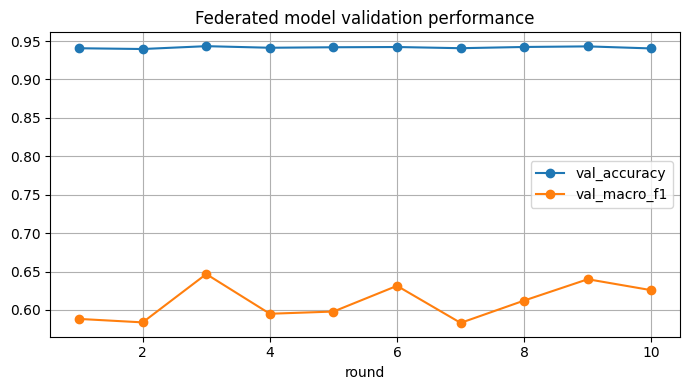

In [16]:
# Reuse the multiclass transformed training data; encode labels as integer classes.
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
ytr_enc = le.fit_transform(np.asarray(y_train_multi))
yva_enc = le.transform(np.asarray(y_val_multi))
yte_enc = le.transform(np.asarray(y_test_multi))
N_CLIENTS=5
ROUNDS=10
rng=np.random.default_rng(SEED)
client_ids=np.array_split(rng.permutation(len(ytr_enc)),N_CLIENTS)
n_features=Xtr.shape[1]
n_classes=len(le.classes_)
# For multiclass SGD, coefficient matrix is (classes, features); initialize global model.
global_model=SGDClassifier(loss="log_loss", alpha=1e-4, random_state=SEED)
global_model.partial_fit(Xtr[:min(10,len(Xtr))], ytr_enc[:min(10,len(Xtr))], classes=np.arange(n_classes))
global_coef=global_model.coef_.copy()
global_intercept=global_model.intercept_.copy()
fed_rounds=[]
for rnd in range(ROUNDS):
    local_coefs=[]; local_intercepts=[]; sizes=[]
    for cid,idx in enumerate(client_ids):
        if len(idx)==0: continue
        local=SGDClassifier(loss="log_loss",alpha=1e-4,random_state=SEED+rnd+cid)
        # Initialize local model by a partial_fit call then overwrite parameters with global weights.
        local.partial_fit(Xtr[idx[:min(10,len(idx))]], ytr_enc[idx[:min(10,len(idx))]], classes=np.arange(n_classes))
        local.coef_=global_coef.copy(); local.intercept_=global_intercept.copy()
        local.t_=1.0
        # One or more local passes; use partial_fit to continue from global parameters.
        for _ in range(2):
            local.partial_fit(Xtr[idx], ytr_enc[idx])
        local_coefs.append(local.coef_.copy()); local_intercepts.append(local.intercept_.copy()); sizes.append(len(idx))
    w=np.asarray(sizes,dtype=float); w/=w.sum()
    global_coef=np.sum([wi*ci for wi,ci in zip(w,local_coefs)],axis=0)
    global_intercept=np.sum([wi*bi for wi,bi in zip(w,local_intercepts)],axis=0)
    global_model.coef_=global_coef.copy(); global_model.intercept_=global_intercept.copy()
    global_model.classes_=np.arange(n_classes); global_model.n_features_in_=n_features; global_model.t_=1.0
    pv=global_model.predict(Xva)
    fed_rounds.append({"round":rnd+1,"val_accuracy":accuracy_score(yva_enc,pv),
                       "val_macro_f1":f1_score(yva_enc,pv,average="macro",zero_division=0)})
fed_history=pd.DataFrame(fed_rounds)
display(fed_history)
fed_history.plot(x="round",y=["val_accuracy","val_macro_f1"],marker="o",figsize=(7,4),grid=True)
plt.title("Federated model validation performance"); plt.tight_layout(); plt.show()

In [17]:
fed_pred=global_model.predict(Xte)
print(classification_report(yte_enc,fed_pred,target_names=le.classes_,digits=4,zero_division=0))
print("Federated accuracy:",accuracy_score(yte_enc,fed_pred))
print("Federated macro-F1:",f1_score(yte_enc,fed_pred,average="macro",zero_division=0))
print("Centralized ExtraTrees macro-F1:",f1_score(y_test_multi,pred_multi,average="macro",zero_division=0))

                       precision    recall  f1-score   support

             Backdoor     0.7740    0.8924    0.8290       994
            DDoS_HTTP     0.7571    0.9213    0.8312      1996
            DDoS_ICMP     0.9931    0.9951    0.9941      4658
             DDoS_TCP     0.6773    1.0000    0.8076      2002
             DDoS_UDP     0.9802    0.9988    0.9894      4863
       Fingerprinting     0.0000    0.0000    0.0000        40
                 MITM     1.0000    1.0000    1.0000        48
               Normal     0.9985    1.0000    0.9992     64626
             Password     0.4366    0.6815    0.5322      2006
        Port_Scanning     0.0000    0.0000    0.0000       902
           Ransomware     0.9865    0.1670    0.2857       437
        SQL_injection     0.4972    0.4385    0.4660      2048
            Uploading     0.6887    0.2837    0.4019      1505
Vulnerability_scanner     0.9370    0.8384    0.8850      2005
                  XSS     0.5531    0.3595    0.4358  

## Section 5 — Threat-aware multi-agent RL in a simulated LoRa environment

This is an abstract simulation for policy comparison, not a validated LoRa physical-layer simulator. The intrusion detector's output is not directly mapped from every network row into radio telemetry; instead, the environment samples threat intensity and channel quality, then compares transmission policies under declared assumptions.

Actions represent discrete transmission profiles. Rewards trade off delivery proxy, latency proxy, energy proxy and threat-associated delivery risk. Keep the word **simulated** in plots and manuscript captions.

In [18]:
PROFILES=[
 {"sf":7,"tp":8,"cr":"4/5","energy":0.7,"latency":0.7},
 {"sf":8,"tp":10,"cr":"4/5","energy":0.9,"latency":0.9},
 {"sf":9,"tp":12,"cr":"4/6","energy":1.1,"latency":1.1},
 {"sf":10,"tp":14,"cr":"4/6","energy":1.4,"latency":1.4},
 {"sf":11,"tp":16,"cr":"4/7","energy":1.8,"latency":1.8},
 {"sf":12,"tp":18,"cr":"4/8","energy":2.2,"latency":2.2},
]
def sim_step(action, threat, channel, rng):
    p=PROFILES[int(action)]
    # Explicit synthetic relationship; not calibrated to SX1276/LoRa airtime.
    z=1.5*channel+0.20*(p["sf"]-7)+0.07*(p["tp"]-8)-0.40*threat
    base=1/(1+np.exp(-z))
    pdr=float(np.clip(base+rng.normal(0,0.035),0,1))
    latency=float(max(0.01,p["latency"]*(1.25-0.35*channel)+rng.normal(0,0.04)))
    energy=float(p["energy"]*(0.9+0.25*pdr))
    reward=1.0*pdr-0.20*latency-0.18*energy-0.60*threat*(1-pdr)
    return pdr,latency,energy,reward
def state_id(channel,threat):
    cb=int(np.clip(channel*5,0,4)); tb=int(threat>=0.5)
    return cb*2+tb

In [19]:
# Multi-agent tabular Q-learning baseline
N_AGENTS=5
EPISODES=300
STEPS=40
N_STATES=10; N_ACTIONS=len(PROFILES)
Q=np.zeros((N_AGENTS,N_STATES,N_ACTIONS))
alpha,gamma=0.12,0.95
epsilon,epsilon_min,epsilon_decay=1.0,0.05,0.985
rng=np.random.default_rng(SEED)
logs=[]
for ep in range(EPISODES):
    rewards=[]; pdrs=[]; lats=[]; ens=[]
    for ag in range(N_AGENTS):
        for _ in range(STEPS):
            channel=rng.uniform(0,1)
            threat=float(rng.beta(1.5+(ep%60)/30,4.0))
            s=state_id(channel,threat)
            a=int(rng.integers(N_ACTIONS)) if rng.random()<epsilon else int(np.argmax(Q[ag,s]))
            pdr,lat,en,r=sim_step(a,threat,channel,rng)
            s2=state_id(float(np.clip(channel+rng.normal(0,.12),0,1)),threat)
            Q[ag,s,a]+=alpha*(r+gamma*np.max(Q[ag,s2])-Q[ag,s,a])
            rewards.append(r);pdrs.append(pdr);lats.append(lat);ens.append(en)
    epsilon=max(epsilon_min,epsilon*epsilon_decay)
    logs.append({"episode":ep+1,"reward":np.mean(rewards),"pdr_proxy":np.mean(pdrs),
                 "latency_proxy":np.mean(lats),"energy_proxy":np.mean(ens),"epsilon":epsilon})
rl_history=pd.DataFrame(logs)
display(rl_history.tail())

,episode,reward,pdr_proxy,latency_proxy,energy_proxy,epsilon
295,296,0.242404,0.718176,1.049251,1.049257,0.05
296,297,0.244449,0.715434,1.036815,1.038258,0.05
297,298,0.238678,0.714078,1.055572,1.048703,0.05
298,299,0.253101,0.720054,1.029779,1.027915,0.05
299,300,0.237610,0.718402,1.055707,1.056371,0.05


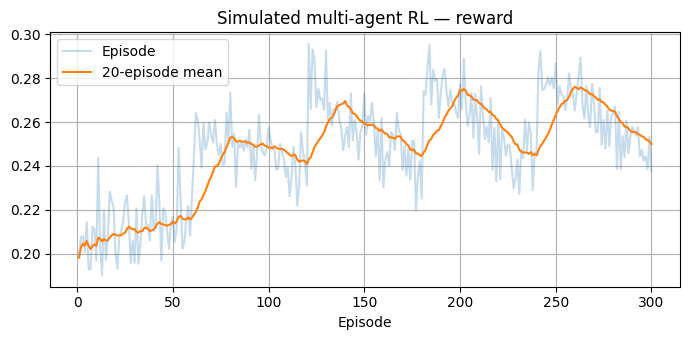

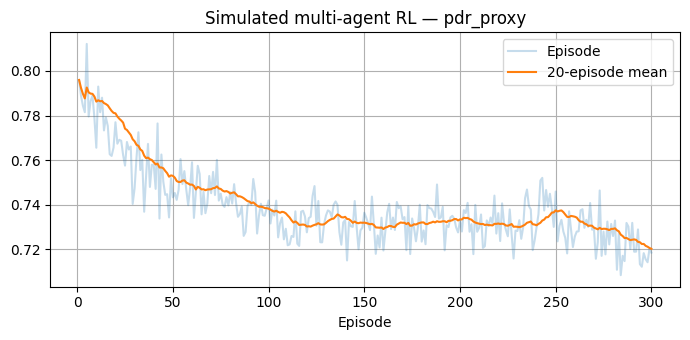

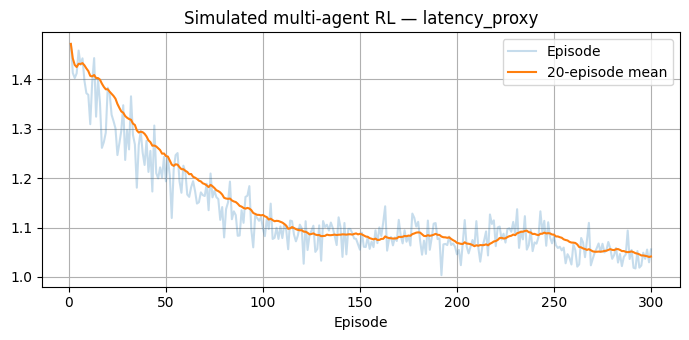

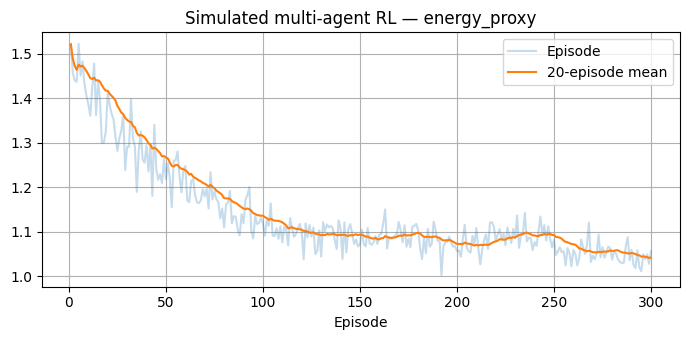

In [20]:
for metric in ["reward","pdr_proxy","latency_proxy","energy_proxy"]:
    plt.figure(figsize=(7,3.5))
    plt.plot(rl_history.episode,rl_history[metric],alpha=.25,label="Episode")
    plt.plot(rl_history.episode,rl_history[metric].rolling(20,min_periods=1).mean(),label="20-episode mean")
    plt.title("Simulated multi-agent RL — "+metric);plt.xlabel("Episode");plt.legend();plt.grid(True);plt.tight_layout();plt.show()

,pdr_proxy,latency_proxy,energy_proxy,reward
Learned Q policy,0.725122,1.031639,1.030099,0.277352
Fixed SF8 profile,0.712168,0.968237,0.970238,0.284544
Random profile,0.810829,1.664967,1.734397,0.126654


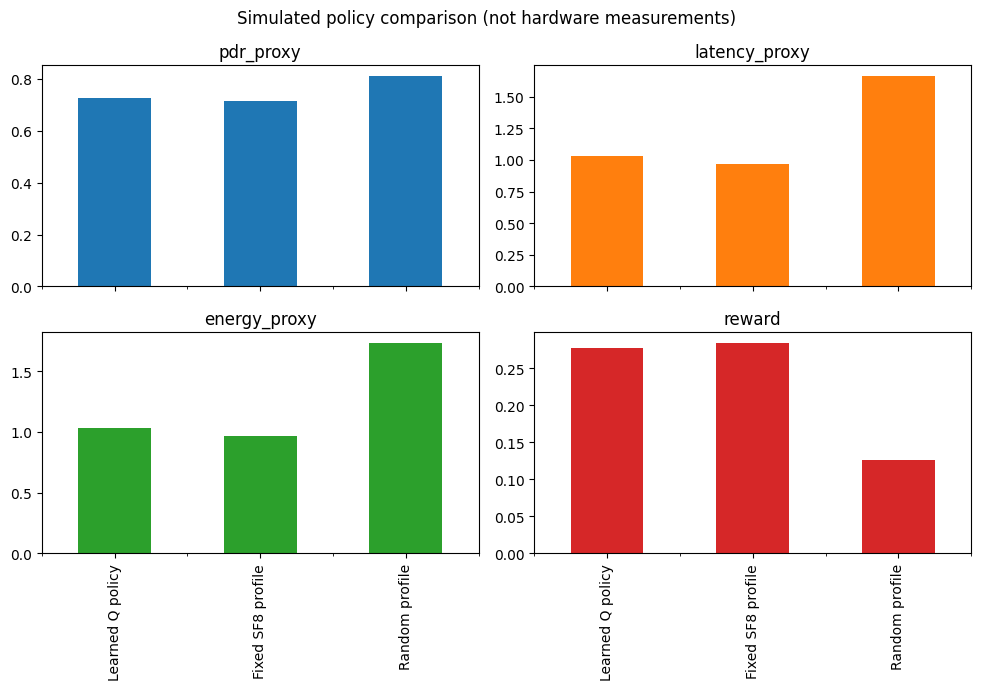

In [21]:
def eval_policy(policy_fn,n=5000,seed=2026):
    r=np.random.default_rng(seed); out=[]
    for i in range(n):
        ag=i%N_AGENTS; ch=r.uniform(0,1); th=float(r.beta(2,4)); s=state_id(ch,th)
        a=int(policy_fn(ag,s,ch,th))
        pdr,lat,en,reward=sim_step(a,th,ch,r)
        out.append([pdr,lat,en,reward,a])
    return pd.DataFrame(out,columns=["pdr_proxy","latency_proxy","energy_proxy","reward","action"])
learned=eval_policy(lambda ag,s,ch,th:np.argmax(Q[ag,s]))
fixed=eval_policy(lambda ag,s,ch,th:1)
random_policy=eval_policy(lambda ag,s,ch,th:np.random.default_rng(ag+s+7).integers(N_ACTIONS))
policy_summary=pd.DataFrame({
 "Learned Q policy":learned[["pdr_proxy","latency_proxy","energy_proxy","reward"]].mean(),
 "Fixed SF8 profile":fixed[["pdr_proxy","latency_proxy","energy_proxy","reward"]].mean(),
 "Random profile":random_policy[["pdr_proxy","latency_proxy","energy_proxy","reward"]].mean()
}).T
display(policy_summary)
policy_summary.plot(kind="bar",subplots=True,layout=(2,2),figsize=(10,7),legend=False)
plt.suptitle("Simulated policy comparison (not hardware measurements)")
plt.tight_layout();plt.show()

## Section 6 — Security validation with AES-GCM

Use standard authenticated encryption. Do not use RL actions, timestamps alone, or a measured entropy score as a cryptographic key. The demo uses a secure random AES key and a fresh 96-bit nonce for each encryption. In a deployed system, nonce uniqueness per key and durable anti-replay state must be guaranteed across reboot and concurrency.

In [22]:
from cryptography.hazmat.primitives.ciphers.aead import AESGCM
import os, json
demo_key=AESGCM.generate_key(bit_length=128)
aead=AESGCM(demo_key)
accepted=set()
def encrypt_message(message:bytes,device="node-01",counter=1):
    nonce=os.urandom(12)
    aad=json.dumps({"device":device,"counter":counter},sort_keys=True).encode()
    ct=aead.encrypt(nonce,message,aad)
    return {"nonce":nonce,"aad":aad,"ciphertext":ct,"id":(device,counter)}
def decrypt_message(packet):
    if packet["id"] in accepted:
        raise ValueError("Replay rejected: packet identifier already accepted")
    plaintext=aead.decrypt(packet["nonce"],packet["ciphertext"],packet["aad"])
    accepted.add(packet["id"])
    return plaintext
packet=encrypt_message(b"temperature=27.4;humidity=61.2",counter=1)
print("Decrypted:",decrypt_message(packet))
try: decrypt_message(packet)
except Exception as e: print("Replay test:",type(e).__name__,str(e))

Decrypted: b'temperature=27.4;humidity=61.2'
Replay test: ValueError Replay rejected: packet identifier already accepted


In [23]:
# Tamper test: flip one ciphertext bit and expect authentication failure.
packet2=encrypt_message(b"sensor_status=normal",counter=2)
bad=dict(packet2)
bad["ciphertext"]=packet2["ciphertext"][:-1]+bytes([packet2["ciphertext"][-1]^1])
try:
    aead.decrypt(bad["nonce"],bad["ciphertext"],bad["aad"])
    print("FAIL: tampering accepted")
except Exception as e:
    print("Tamper rejected:",type(e).__name__)

Tamper rejected: InvalidTag


## Section 7 — Statistical analysis and ablation plan

A single run is not sufficient for a journal-level claim. Repeat the full pipeline with multiple seeds and report mean ± standard deviation or confidence intervals. Suggested ablations:
- centralized vs federated IDS;
- binary vs multiclass IDS;
- threat-aware reward vs no threat term;
- fixed vs learned transmission profile;
- five vs ten vs twenty simulated clients;
- IID vs label-skewed (non-IID) client partitions;
- low, medium and high simulated attack prevalence;
- reward-weight sensitivity.

The simulator's PDR/latency/energy are synthetic proxies. Validate with a radio simulator or physical LoRa nodes before making real communication-performance claims.

In [24]:
# Basic experiment artifact export
OUT="/content/edgeiiot_lorawan_results"
os.makedirs(OUT,exist_ok=True)
fed_history.to_csv(OUT+"/federated_validation_history.csv",index=False)
rl_history.to_csv(OUT+"/simulated_rl_training_history.csv",index=False)
policy_summary.to_csv(OUT+"/simulated_policy_comparison.csv")
central_summary={
 "dataset_csv":os.path.basename(CSV_PATH),
 "sample_fraction":SAMPLE_FRAC,
 "rows_used":int(len(df)),
 "features_after_filtering":int(features.shape[1]),
 "central_multiclass_accuracy":float(accuracy_score(y_test_multi,pred_multi)),
 "central_multiclass_balanced_accuracy":float(balanced_accuracy_score(y_test_multi,pred_multi)),
 "central_multiclass_macro_f1":float(f1_score(y_test_multi,pred_multi,average="macro",zero_division=0)),
 "federated_multiclass_accuracy":float(accuracy_score(yte_enc,fed_pred)),
 "federated_multiclass_macro_f1":float(f1_score(yte_enc,fed_pred,average="macro",zero_division=0)),
 "rl_episodes":EPISODES,"rl_agents":N_AGENTS,"seed":SEED,
 "radio_metrics_are_simulated":True
}
with open(OUT+"/summary_metrics.json","w") as f: json.dump(central_summary,f,indent=2)
print(json.dumps(central_summary,indent=2))

{
  "dataset_csv": "DNN-EdgeIIoT-dataset.csv",
  "sample_fraction": 0.2,
  "rows_used": 443834,
  "features_after_filtering": 42,
  "central_multiclass_accuracy": 0.9820879380850992,
  "central_multiclass_balanced_accuracy": 0.9004406167281037,
  "central_multiclass_macro_f1": 0.8779330577691777,
  "federated_multiclass_accuracy": 0.9414422026203432,
  "federated_multiclass_macro_f1": 0.6304697678580785,
  "rl_episodes": 300,
  "rl_agents": 5,
  "seed": 42,
  "radio_metrics_are_simulated": true
}


In [25]:
import shutil
shutil.make_archive("/content/edgeiiot_lorawan_results","zip",OUT)
from google.colab import files
files.download("/content/edgeiiot_lorawan_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
# Audit exact duplicates and suspicious/identifier-like features.
print("Rows:", len(df), "| exact duplicate rows:", int(df.duplicated().sum()))
suspicious_tokens = (
    "ip.src", "ip.dst", "src_host", "dst_host", "srcport", "dstport",
    "mac", "hostname", "uri", "mqtt.topic", "mqtt.protoname",
    "dns.qry", "payload", "file_data", "timestamp", "frame.time"
)
suspect_cols = [c for c in features.columns
                if any(tok in c.lower() for tok in suspicious_tokens)]
print("Suspicious/identifier-like feature candidates:", suspect_cols)
print("Class distribution (Attack_type):")
display(df["Attack_type"].value_counts(normalize=True).rename("proportion").to_frame())
# Lightweight duplicate check on a bounded sample to avoid a full high-dimensional groupby.
audit_n = min(50000, len(features))
audit = features.iloc[:audit_n].copy()
audit["__target__"] = df["Attack_type"].astype(str).iloc[:audit_n].to_numpy()
audit["__row_hash__"] = pd.util.hash_pandas_object(features.iloc[:audit_n], index=False).astype("uint64")
conflicts = audit.groupby("__row_hash__")["__target__"].nunique()
print("Conflicting labels among identical hashed feature rows in audit sample:",
      int((conflicts > 1).sum()))


Rows: 443834 | exact duplicate rows: 155
Suspicious/identifier-like feature candidates: ['dns.qry.name', 'dns.qry.name.len', 'dns.qry.qu', 'mqtt.protoname', 'mqtt.topic', 'mqtt.topic_len']
Class distribution (Attack_type):


,proportion
Attack_type,
Normal,0.728038
DDoS_UDP,0.054779
DDoS_ICMP,0.052468
SQL_injection,0.023072
Password,0.022599
Vulnerability_scanner,0.022581
DDoS_TCP,0.022558
DDoS_HTTP,0.022490
Uploading,0.016957


Conflicting labels among identical hashed feature rows in audit sample: 2


In [28]:
from sklearn.metrics import precision_recall_fscore_support
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
import time

baseline_models = {
    "ExtraTrees": ExtraTreesClassifier(n_estimators=250, class_weight="balanced",
                                       random_state=SEED, n_jobs=-1),
    "RandomForest": RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                           random_state=SEED, n_jobs=-1),
    "LogisticRegression": LogisticRegression(max_iter=500, class_weight="balanced",
                                             random_state=SEED)
}
baseline_rows = []
for name, model in baseline_models.items():
    t0 = time.time()
    model.fit(Xtr, y_train_multi)
    fit_s = time.time() - t0
    pred = model.predict(Xte)
    prec, rec, f1m, _ = precision_recall_fscore_support(
        y_test_multi, pred, average="macro", zero_division=0
    )
    baseline_rows.append({
        "model": name, "accuracy": accuracy_score(y_test_multi, pred),
        "balanced_accuracy": balanced_accuracy_score(y_test_multi, pred),
        "macro_precision": prec, "macro_recall": rec, "macro_f1": f1m,
        "weighted_f1": f1_score(y_test_multi, pred, average="weighted", zero_division=0),
        "fit_seconds": fit_s
    })
baseline_table = pd.DataFrame(baseline_rows).sort_values("macro_f1", ascending=False)
display(baseline_table)
baseline_table.to_csv("/content/centralized_baseline_comparison.csv", index=False)


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,fit_seconds
1,RandomForest,0.983631,0.914950,0.886552,0.914950,0.888375,0.983987,54.991298
0,ExtraTrees,0.982088,0.900441,0.876274,0.900441,0.877933,0.982488,53.283404
2,LogisticRegression,0.937567,0.746314,0.708687,0.746314,0.682644,0.939811,202.668185


In [29]:
# Dirichlet label-skew partition: alpha small => more heterogeneous clients.
def dirichlet_partition(y, n_clients=5, alpha=0.3, seed=2026):
    y = np.asarray(y)
    rng = np.random.default_rng(seed)
    client_idx = [[] for _ in range(n_clients)]
    for cls in np.unique(y):
        cls_idx = np.where(y == cls)[0]
        rng.shuffle(cls_idx)
        proportions = rng.dirichlet(np.repeat(alpha, n_clients))
        cuts = (np.cumsum(proportions)[:-1] * len(cls_idx)).astype(int)
        for cid, chunk in enumerate(np.split(cls_idx, cuts)):
            client_idx[cid].extend(chunk.tolist())
    return [np.asarray(sorted(ix), dtype=int) for ix in client_idx]

dirichlet_clients = dirichlet_partition(ytr_enc, n_clients=5, alpha=0.3, seed=2026)
partition_rows = []
for cid, ix in enumerate(dirichlet_clients):
    counts = pd.Series(ytr_enc[ix]).value_counts().to_dict()
    partition_rows.append({
        "client": cid, "n_samples": len(ix),
        "n_classes_present": len(counts),
        "class_counts_encoded": str(dict(sorted(counts.items())))
    })
partition_audit = pd.DataFrame(partition_rows)
display(partition_audit)
print("Total assigned:", sum(map(len, dirichlet_clients)), "of", len(ytr_enc))
assert sum(map(len, dirichlet_clients)) == len(ytr_enc)


,client,n_samples,n_classes_present,class_counts_encoded
0,0,120974,12,"{1: 451, 2: 635, 3: 2390, 5: 1, 6: 50, 7: 1113..."
1,1,17074,14,"{1: 3487, 2: 4, 3: 1145, 4: 4472, 5: 19, 6: 24..."
2,2,35324,14,"{0: 5, 1: 1711, 2: 13747, 3: 1, 4: 4111, 5: 41..."
3,3,100005,14,"{0: 539, 1: 679, 2: 459, 3: 2868, 4: 72, 5: 2,..."
4,4,10676,15,"{0: 2638, 1: 61, 2: 58, 3: 4, 4: 6905, 5: 65, ..."


Total assigned: 284053 of 284053


In [30]:
# Bootstrap CIs for the centralized ExtraTrees model on the held-out test set.
from sklearn.metrics import f1_score, accuracy_score
yt = np.asarray(y_test_multi)
yp = np.asarray(pred_multi)
rng = np.random.default_rng(2026)
B = 1000
boot_acc, boot_macro_f1 = [], []
n = len(yt)
for _ in range(B):
    ix = rng.integers(0, n, size=n)
    boot_acc.append(accuracy_score(yt[ix], yp[ix]))
    boot_macro_f1.append(f1_score(yt[ix], yp[ix], labels=np.unique(yt), average="macro", zero_division=0))
ci_table = pd.DataFrame([
    {"metric":"accuracy", "estimate":accuracy_score(yt,yp),
     "ci95_low":np.quantile(boot_acc,0.025), "ci95_high":np.quantile(boot_acc,0.975)},
    {"metric":"macro_f1", "estimate":f1_score(yt,yp,average="macro",zero_division=0),
     "ci95_low":np.quantile(boot_macro_f1,0.025), "ci95_high":np.quantile(boot_macro_f1,0.975)}
])
display(ci_table)
ci_table.to_csv("/content/centralized_bootstrap_ci.csv", index=False)


,metric,estimate,ci95_low,ci95_high
0,accuracy,0.982088,0.981209,0.982967
1,macro_f1,0.877933,0.870771,0.885352


In [31]:
# Basic experiment artifact export
OUT="/content/edgeiiot_lorawan_results"
os.makedirs(OUT,exist_ok=True)
fed_history.to_csv(OUT+"/federated_validation_history.csv",index=False)
rl_history.to_csv(OUT+"/simulated_rl_training_history.csv",index=False)
policy_summary.to_csv(OUT+"/simulated_policy_comparison.csv")
central_summary={
 "dataset_csv":os.path.basename(CSV_PATH),
 "sample_fraction":SAMPLE_FRAC,
 "rows_used":int(len(df)),
 "features_after_filtering":int(features.shape[1]),
 "central_multiclass_accuracy":float(accuracy_score(y_test_multi,pred_multi)),
 "central_multiclass_balanced_accuracy":float(balanced_accuracy_score(y_test_multi,pred_multi)),
 "central_multiclass_macro_f1":float(f1_score(y_test_multi,pred_multi,average="macro",zero_division=0)),
 "federated_multiclass_accuracy":float(accuracy_score(yte_enc,fed_pred)),
 "federated_multiclass_macro_f1":float(f1_score(yte_enc,fed_pred,average="macro",zero_division=0)),
 "rl_episodes":EPISODES,"rl_agents":N_AGENTS,"seed":SEED,
 "radio_metrics_are_simulated":True
}
with open(OUT+"/summary_metrics.json","w") as f: json.dump(central_summary,f,indent=2)
print(json.dumps(central_summary,indent=2))

{
  "dataset_csv": "DNN-EdgeIIoT-dataset.csv",
  "sample_fraction": 0.2,
  "rows_used": 443834,
  "features_after_filtering": 42,
  "central_multiclass_accuracy": 0.9820879380850992,
  "central_multiclass_balanced_accuracy": 0.9004406167281037,
  "central_multiclass_macro_f1": 0.8779330577691777,
  "federated_multiclass_accuracy": 0.9414422026203432,
  "federated_multiclass_macro_f1": 0.6304697678580785,
  "rl_episodes": 300,
  "rl_agents": 5,
  "seed": 42,
  "radio_metrics_are_simulated": true
}


In [33]:
{
  "dataset_csv": "DNN-EdgeIIoT-dataset.csv",
  "sample_fraction": 0.2,
  "rows_used": 443834,
  "features_after_filtering": 42,
  "central_multiclass_accuracy": 0.9820879380850992,
  "central_multiclass_balanced_accuracy": 0.9004406167281037,
  "central_multiclass_macro_f1": 0.8779330577691777,
  "federated_multiclass_accuracy": 0.9414422026203432,
  "federated_multiclass_macro_f1": 0.6304697678580785,
  "rl_episodes": 300,
  "rl_agents": 5,
  "seed": 42,
  "radio_metrics_are_simulated": True
}

{'dataset_csv': 'DNN-EdgeIIoT-dataset.csv',
 'sample_fraction': 0.2,
 'rows_used': 443834,
 'features_after_filtering': 42,
 'central_multiclass_accuracy': 0.9820879380850992,
 'central_multiclass_balanced_accuracy': 0.9004406167281037,
 'central_multiclass_macro_f1': 0.8779330577691777,
 'federated_multiclass_accuracy': 0.9414422026203432,
 'federated_multiclass_macro_f1': 0.6304697678580785,
 'rl_episodes': 300,
 'rl_agents': 5,
 'seed': 42,
 'radio_metrics_are_simulated': True}

In [34]:
import shutil
shutil.make_archive("/content/edgeiiot_lorawan_results","zip",OUT)
from google.colab import files
files.download("/content/edgeiiot_lorawan_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Section 8 — Limitations and scalability

1. Edge-IIoTset is general IoT/IIoT cybersecurity traffic, not a LoRaWAN PHY trace dataset.
2. Simulated client partitions do not establish privacy guarantees or real multi-gateway deployment performance.
3. The federated model is an SGD baseline; it is not a federated DDQN implementation.
4. The Q-learning radio environment is abstract and uncalibrated.
5. AEAD tests are functional demonstrations, not formal cryptographic proofs.
6. Full evaluation should include repeated seeds, confidence intervals, ablation studies, class-wise error analysis and, ideally, validated radio simulation or hardware trials.

## Section 9 — Conclusion and manuscript structure

Suggested manuscript organization preserving the original paper's nine major sections:

1. Introduction
   - 1.1 Research contributions
   - 1.2 Paper organisation
2. Literature review
   - 2.1 IoT/LoRaWAN security
   - 2.2 Adaptive transmission optimization
   - 2.3 Federated intrusion detection and multi-agent learning
   - 2.4 Research gaps
3. System model and framework architecture
   - 3.1 Network and threat model
   - 3.2 Federated IDS and threat-aware policy architecture
   - 3.3 Implementation environment
4. Mathematical modelling
   - 4.1 Feature representation
   - 4.2 Intrusion detection and threat score
   - 4.3 Federated aggregation
   - 4.4 Simulated MDP and multi-agent learning
5. Security analysis
   - 5.1 Security objectives
   - 5.2 Assumptions
   - 5.3 AEAD, tamper and replay checks
6. Experimental setup and reproducibility
7. Results and discussion
   - 7.1 Dataset and class distribution
   - 7.2 Centralized IDS
   - 7.3 Federated convergence
   - 7.4 Simulated RL convergence and policy comparison
   - 7.5 Ablation and sensitivity
   - 7.6 Statistical validation
8. Limitations, scalability and future directions
9. Conclusion

Dataset citation: Ferrag et al., “Edge-IIoTset: A New Comprehensive Realistic Cyber Security Dataset of IoT and IIoT Applications for Centralized and Federated Learning,” IEEE Access, 2022, DOI: 10.1109/ACCESS.2022.3165809. Check the dataset page for its CC BY-NC-SA 4.0 license and cite the original dataset paper.